# Tutorial: Benchmarking Repeated Auctions with `dynamicauc`


Welcome to the **DynamicAuc** tutorial.

This notebook will guide you through:
# Table of Contents
1. [Setup and Imports](#1-setup-and-imports)
2. [Creating Scenarios](#2-creating-scenarios)
   - 2.1 [Using a Preset](#21-using-a-preset)
   - 2.2 [Using a Builder](#22-using-a-builder)
   - 2.3 [Using a Preset Override](#23-using-a-preset-override)
3. [RL Integration](#3-rl-integration)
    - 3.1 [Gym Environment](#31-gym-environment)
    - 3.2 [Policy Instantiation](#32-policy-instantiation)
    - 3.3 [Running Episodes](#33-running-episodes)
4. [Visualization](#4-visualization)  


## **1. Setup and Imports**

In [1]:

import gymnasium as gym
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import dynamicauc as dac

plt.style.use('seaborn-v0_8-whitegrid')


## **2. Creating Scenarios**

A scenario is a dataclass `Scenario` in `dynamicauc` defines the environment in which the repeated auction takes place. It includes : 
- The user features ($u$)
- The reward kernel ($\lambda$ and $\kappa$)
- The auction rules (e.g., second-price, first-price)
- The arrival process of auction opportunities
- The display features sampler ($X$)
- The exogenous context sampler
- The horizon of the simulation ($T$)

There are three ways to create a scenario in `dynamicauc`:
1. **Using a preset**: Predefined scenarios that can be easily loaded.
2. **Using a builder**: Custom scenarios created programmatically.
3. **Using a preset override**: Modifying existing presets to fit specific needs.

### **2.1 Using a Preset** :

You can see a list of available presets and their descriptions using the following code:

In [4]:

print("Available presets:", dac.list_scenarios())
print(dac.describe_scenarios())

Available presets: ['saturation-first-price-uniform', 'recency-second-price-lognormal', 'mixed-first-price-exponential']
Available Scenarios
saturation-first-price-uniform      | Saturation kernel with first-price auction and uniform competition
recency-second-price-lognormal      | Recency kernel with second-price auction and lognormal competition
mixed-first-price-exponential       | Mixed kernel (immediate + delayed) with first-price and exponential competition

* Use get_scenario_info(scenario_id) for full technical specs.


In [5]:

scenario = dac.make("saturation-first-price-uniform")

info = dac.get_scenario_info("saturation-first-price-uniform")
print(f"\nScenario Description: {info['description']}")


TECHNICAL SPECIFICATIONS: saturation-first-price-uniform
Description: Saturation kernel with first-price auction and uniform competition
------------------------------------------------------------
kernel:
  name: saturation
  params:
    base_rate: 0.5
    saturation_scale: 10.0
    delay_rate: 0.1
auction:
  name: first-price
competition:
  name: uniform
  params:
    low: 0.0
    high: 1.0
arrival:
  name: poisson
  params:
    breakpoints: [5.0]
    intensities: [0.1, 1.2]
display:
  name: iid
  params:
    dim: 3
exogenous:
  name: trivial
horizon: 10.0
user_features: [0.5, 0.8, 0.02]


Scenario Description: Saturation kernel with first-price auction and uniform competition


### **2.1 Using a Builder :**

In [ ]:

scenario_custom = (
    dac.ScenarioBuilder()
    .with_kernel("saturation", base_rate=0.5, saturation_scale=10.0)
    .with_auction("first-price")
    .with_competition("uniform", low=0.0, high=20.0)
    .with_arrival("poisson", breakpoints=[5.0], intensities=[0.1, 1.2])
    .with_display("iid", dim=3)
    .with_horizon(10.0)
    .with_user_features([0.5, 0.8, 0.02])
    .build()
)


### **2.1 Using a Presset Override** :

In [ ]:

scenario_high_sat = dac.make(
    "saturation-first-price-uniform",
    horizon=20.0,
    kernel_saturation_scale=50.0
)


#### *Note on Parameter Overrides*
The `make` function uses a **flattened prefix convention** to modify nested parameters. Instead of passing complex dictionaries, use the `prefix_parameter` syntax.

The factory logic splits keys at the first underscore to surgically update a primitive's `params` without overwriting the entire component (like the model type or distribution name).

---

#### *Quick Usage Reference*
* **Top-level:** `horizon=20.0`, `user_features=[...]`
* **Nested:** `[component]_[parameter]=[value]`

| Target Component | flattened Key Example | Maps to Preset Path |
| :--- | :--- | :--- |
| **Kernel** | `kernel_saturation_scale=5.0` | `kernel['params']['saturation_scale']` |
| **Competition** | `competition_low=0.1` | `competition['params']['low']` |
| **Arrival** | `arrival_intensities=[1.5]` | `arrival['params']['intensities']` |

**Example:**

In [6]:
scenario_smaller_bound = dac.make("saturation-first-price-uniform", competition_high=0.2, kernel_saturation_scale=40.0, 
                                  kernel_delay_rate=0.1, horizon=50.0, kernel_base_rate=0.9) 
print(f"scenario_smaller_bound competition params: {scenario_smaller_bound.competition.high}, {scenario_smaller_bound.competition.low}")
print(f"scenario_smaller_bound kernel params: {scenario_smaller_bound.kernel.saturation_scale}, {scenario_smaller_bound.kernel.delay_rate}")

scenario_smaller_bound competition params: 0.2, 0.0
scenario_smaller_bound kernel params: 40.0, 0.1


## **3. RL Integration**

### **3.1 Gym Environment**

You can easily integrate `dynamicauc` scenarios with the Gymnasium API for reinforcement learning experiments with the class `AuctionEnv`. 

Here's how to create a Gym environment from a `dynamicauc` scenario, using the Gymnasium `make` function with parameter overrides, to use it you only have to import `dynamicauc` and `gymnasium` and then use the following code:

In [8]:

env = gym.make("DynamicAuction-v0", scenario=scenario_smaller_bound, stochastic_reward=True)

obs, info = env.reset(seed=42)
history = []

### **3.2 Policy Instantiation**

The `dynamicauc` library provides a variety of built-in policies that can be easily instantiated and used for benchmarking. 

For example, to create a simple fixed-price policy, you can use the following code:

In [9]:
policy = dac.FiPlaPolicy()

### **3.3 Running episodes**

In [ ]:

total_reward = 0.0
terminated = False
truncated = False

while not (terminated or truncated):
    bid = policy.bid(obs)
    expected_value = env.unwrapped.kernel.expected_reward(
        u=obs["user_features"],
        x=obs["display_features"],
        ctx=obs["ctx"].item(),
        y_func=env.unwrapped.state.y_func,
        t=obs["t"].item(),
        horizon=scenario.horizon
    )
    
    obs, reward, terminated, truncated, info = env.step(bid)
    
    history.append({
            "time": obs['t'].item(),
            "context": obs["ctx"].item(),
            "expected_value": expected_value,
            "won": info["auction"]["won"],
            "reward": reward
        })

    current_t = obs['t'].item()
    comp_bid = info["auction"]["competing_bid"]
    
    print(f"t={current_t:.2f} | Bid: {bid:.2f} | Compete: {comp_bid:.2f} | Reward: {reward:.4f}")
    
    total_reward += reward
print(f"Episode Finished. Total Reward: {total_reward:.2f}")
env.close()


t=5.33 | Bid: 0.22 | Compete: 0.11 | Reward: 0.7826
t=6.97 | Bid: 0.17 | Compete: 0.16 | Reward: 1.8312
t=7.87 | Bid: 0.11 | Compete: 0.07 | Reward: 0.8930
t=10.15 | Bid: 0.07 | Compete: 0.14 | Reward: 0.0000
t=10.77 | Bid: 0.00 | Compete: 0.18 | Reward: 0.0000
t=10.85 | Bid: 0.00 | Compete: 0.12 | Reward: 0.0000
t=11.29 | Bid: 0.00 | Compete: 0.14 | Reward: 0.0000
t=11.29 | Bid: 0.00 | Compete: 0.13 | Reward: 0.0000
t=11.94 | Bid: 0.00 | Compete: 0.10 | Reward: 0.0000
t=13.53 | Bid: 0.00 | Compete: 0.12 | Reward: 0.0000
t=13.76 | Bid: 0.00 | Compete: 0.07 | Reward: 0.0000
t=14.00 | Bid: 0.00 | Compete: 0.10 | Reward: 0.0000
t=15.21 | Bid: 0.00 | Compete: 0.10 | Reward: 0.0000
t=15.23 | Bid: 0.00 | Compete: 0.05 | Reward: 0.0000
t=17.97 | Bid: 0.00 | Compete: 0.00 | Reward: 0.0000
t=19.06 | Bid: 0.00 | Compete: 0.11 | Reward: 0.0000
t=19.66 | Bid: 0.00 | Compete: 0.13 | Reward: 0.0000
t=20.95 | Bid: 0.00 | Compete: 0.18 | Reward: 0.0000
t=21.67 | Bid: 0.00 | Compete: 0.07 | Reward: 0.0

## **4. Visualization**

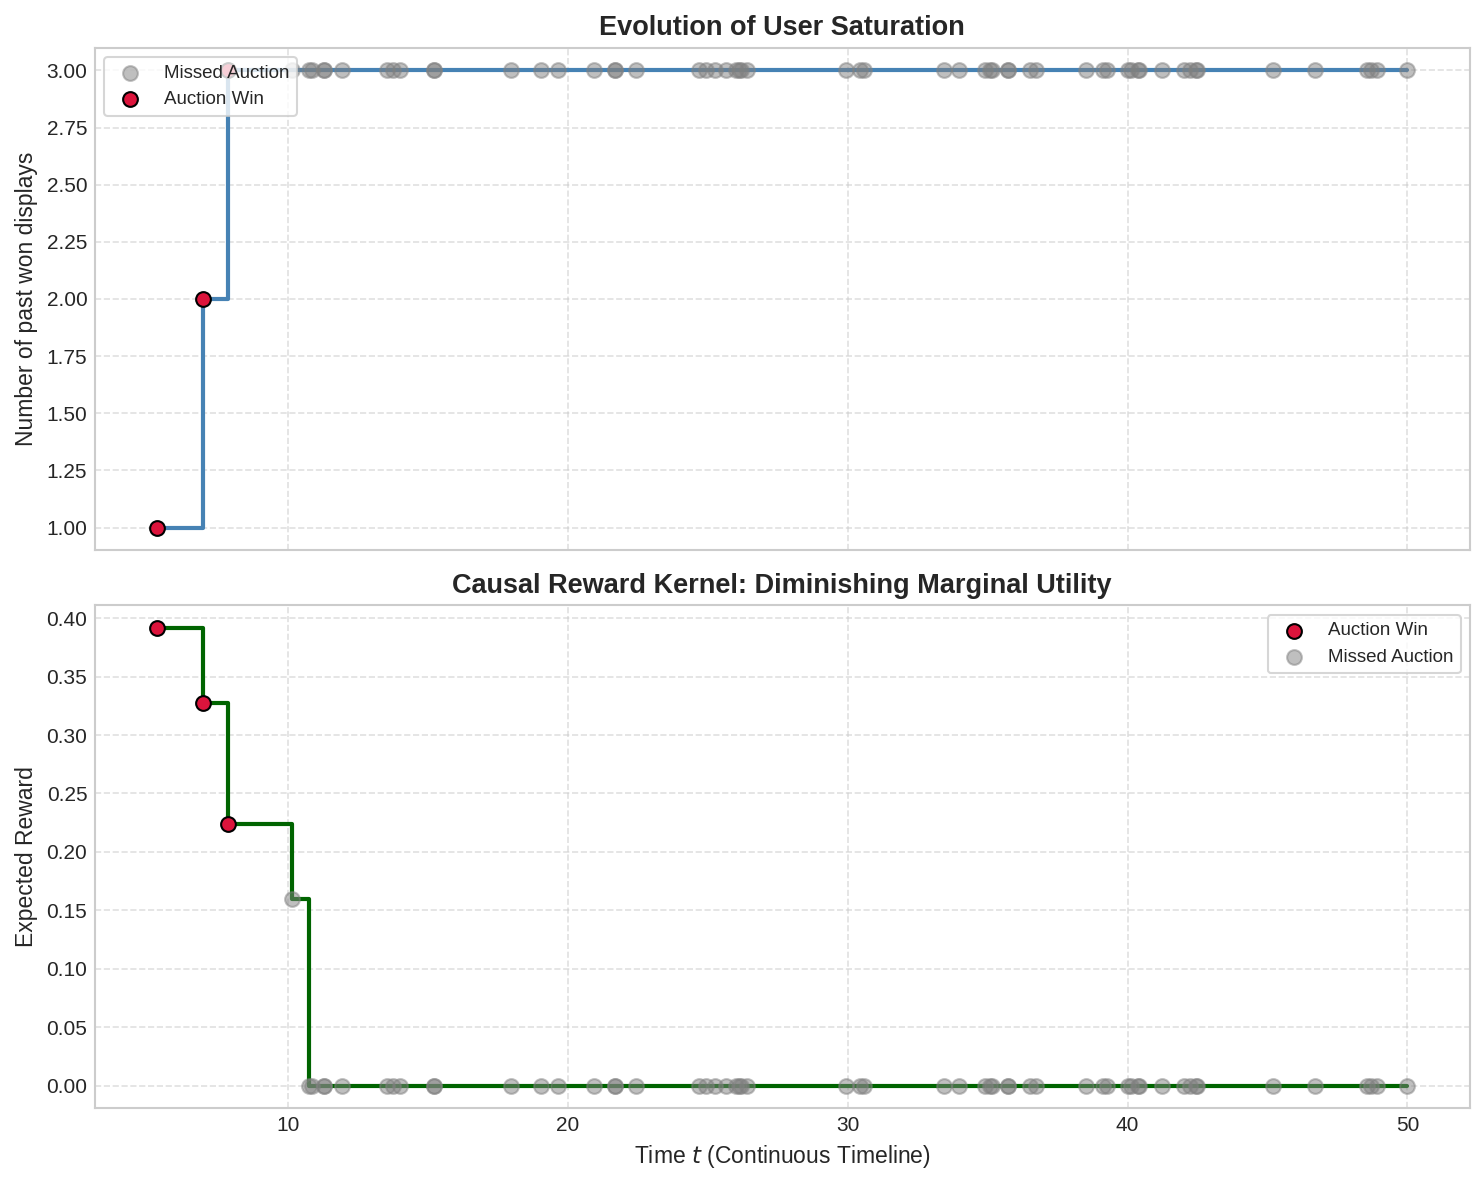

In [15]:
def plot_value_dynamics(history):
    df = pd.DataFrame(history)
    wins = df[df['won']]
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, dpi=150)
    
    ax1.step(df['time'], df['context'], where='post', color='steelblue', 
             linewidth=2)
    
    ax1.scatter(df[~df['won']]['time'], df[~df['won']]['context'], 
                color='gray', alpha=0.5, s=50, label='Missed Auction', zorder=3)
    ax1.scatter(wins['time'], wins['context'], color='crimson', 
                edgecolor='black', s=50, label='Auction Win', zorder=3)
    
    ax1.set_ylabel("Number of past won displays", fontsize=11)
    ax1.set_title("Evolution of User Saturation", fontsize=13, weight='bold')
    ax1.legend(frameon=True, loc='upper left', fontsize=9)
    ax1.grid(True, linestyle='--', alpha=0.6)
    
    # --- PANEL 2: The Reward Kernel (Causal Response) ---
    ax2.step(df['time'], df['expected_value'], where='post', color='darkgreen', 
             linewidth=2)
    
    ax2.scatter(wins['time'], wins['expected_value'], color='crimson', 
                edgecolor='black', s=50, label='Auction Win', zorder=3)
    ax2.scatter(df[~df['won']]['time'], df[~df['won']]['expected_value'], 
                color='gray', alpha=0.5, s=50, label='Missed Auction', zorder=3)
    
    ax2.set_xlabel(r"Time $t$ (Continuous Timeline)", fontsize=11)
    ax2.set_ylabel("Expected Reward", fontsize=11)
    ax2.set_title("Causal Reward Kernel: Diminishing Marginal Utility", fontsize=13, weight='bold')
    ax2.legend(frameon=True, loc='upper right', fontsize=9)
    ax2.grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

plot_value_dynamics(history)

## 5. Simulator

In [ ]:

from dynamicauc.simulator import Simulator

sim = Simulator(scenario, campaign_cfg={
    "horizon": 10.0,
    "n_runs": 100,
    "seed": 42,
})

auctions_df, displays_df, conversions_df, summary_df = sim.run()

print(f"Average Win Rate: {summary_df['win_rate'].mean():.2%}")
print(f"Mean Conversions per Campaign: {summary_df['n_conversions'].mean():.2f}")
